# Customer Segmentation Using Clustering

## 1. Introduction

Customer segmentation is an unsupervised machine learning task
that groups customers according to similarities in their purchasing
behaviour.

This project implements and compares two clustering algorithms:

1. K-Means Clustering
2. Agglomerative Hierarchical Clustering

The Online Retail dataset is used to derive customer-level
features from transaction records.

The models are evaluated using the Silhouette Score,
Davies-Bouldin Index, and Calinski-Harabasz Index.

The project also includes the Elbow method, a hierarchical
clustering dendrogram, PCA visualizations, and a t-SNE
visualization to help interpret the resulting clusters.

## 2. Dataset Description

The dataset contains transaction records from an online retail store.

Each record describes a product transaction and may include
the invoice number, product code, quantity, invoice date,
unit price, customer identifier, and country.

Since clustering is performed at the customer level, transaction
records will be aggregated into customer-level behavioural features.

The original dataset does not provide the cluster labels required
for supervised learning. Therefore, clustering algorithms will
discover groups based on similarities in the derived features.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from scipy.cluster.hierarchy import linkage, dendrogram

from IPython.display import display

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
file_path = "../data/clustering/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data Preprocessing

Before applying clustering, the transaction data must be cleaned.

The preprocessing steps are:

1. Remove duplicate transactions.
2. Remove records without a CustomerID.
3. Convert InvoiceDate to datetime format.
4. Exclude cancelled invoices.
5. Retain transactions with positive quantities and unit prices.

These steps help create meaningful customer-level purchasing features.

In [4]:
retail = df.copy()

# Remove duplicate transactions
retail = retail.drop_duplicates()

# Remove transactions without a customer identifier
retail = retail.dropna(subset=["CustomerID"]).copy()

# Convert relevant columns to their appropriate types
retail["CustomerID"] = retail["CustomerID"].astype(int)
retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"])

# Remove cancelled invoices
retail = retail[
    ~retail["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Keep transactions with positive quantity and unit price
retail = retail[
    (retail["Quantity"] > 0) &
    (retail["UnitPrice"] > 0)
].copy()

# Calculate the monetary value of each transaction line
retail["Sales"] = retail["Quantity"] * retail["UnitPrice"]

print("Cleaned dataset shape:", retail.shape)
print("Unique customers:", retail["CustomerID"].nunique())

display(retail.head())

Cleaned dataset shape: (392692, 9)
Unique customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 4. Customer-Level Feature Engineering

The original dataset contains individual transaction records. To perform
customer segmentation, the records are aggregated by CustomerID.

The following features are created:

- Frequency: Number of distinct invoices associated with a customer.
- Monetary: Total monetary value of the customer's purchases.
- AverageOrderValue: Average total value per invoice.
- UniqueProducts: Number of distinct products purchased by the customer.

These features represent purchasing frequency, spending behaviour,
average order value, and product variety.

In [5]:
customer_features = retail.groupby("CustomerID").agg(
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Sales", "sum"),
    UniqueProducts=("StockCode", "nunique")
)

customer_features["AverageOrderValue"] = (
    customer_features["Monetary"] /
    customer_features["Frequency"]
)

# Keep a consistent feature order
feature_columns = [
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "UniqueProducts"
]

customer_features = customer_features[feature_columns]

# Remove any invalid values
customer_features = customer_features.replace(
    [np.inf, -np.inf], np.nan
).dropna()

customer_features = customer_features[
    (customer_features > 0).all(axis=1)
]

print("Customer-level dataset shape:", customer_features.shape)
print("\nCustomer features:")
display(customer_features.head())

print("\nFeature summary:")
display(customer_features.describe().T)

Customer-level dataset shape: (4338, 4)

Customer features:


,Frequency,Monetary,AverageOrderValue,UniqueProducts
CustomerID,,,,
12346,1,77183.60,77183.600000,1
12347,7,4310.00,615.714286,103
12348,4,1797.24,449.310000,22
12349,1,1757.55,1757.550000,73
12350,1,334.40,334.400000,17



Feature summary:


,count,mean,std,min,25%,50%,75%,max
Frequency,4338.0,4.272015,7.697998,1.00,1.000000,2.00,5.000000,209.00
Monetary,4338.0,2048.688081,8985.230220,3.75,306.482500,668.57,1660.597500,280206.02
AverageOrderValue,4338.0,417.645735,1796.511343,3.45,177.867083,291.94,428.280625,84236.25
UniqueProducts,4338.0,61.501153,85.366768,1.00,16.000000,35.00,77.000000,1787.00


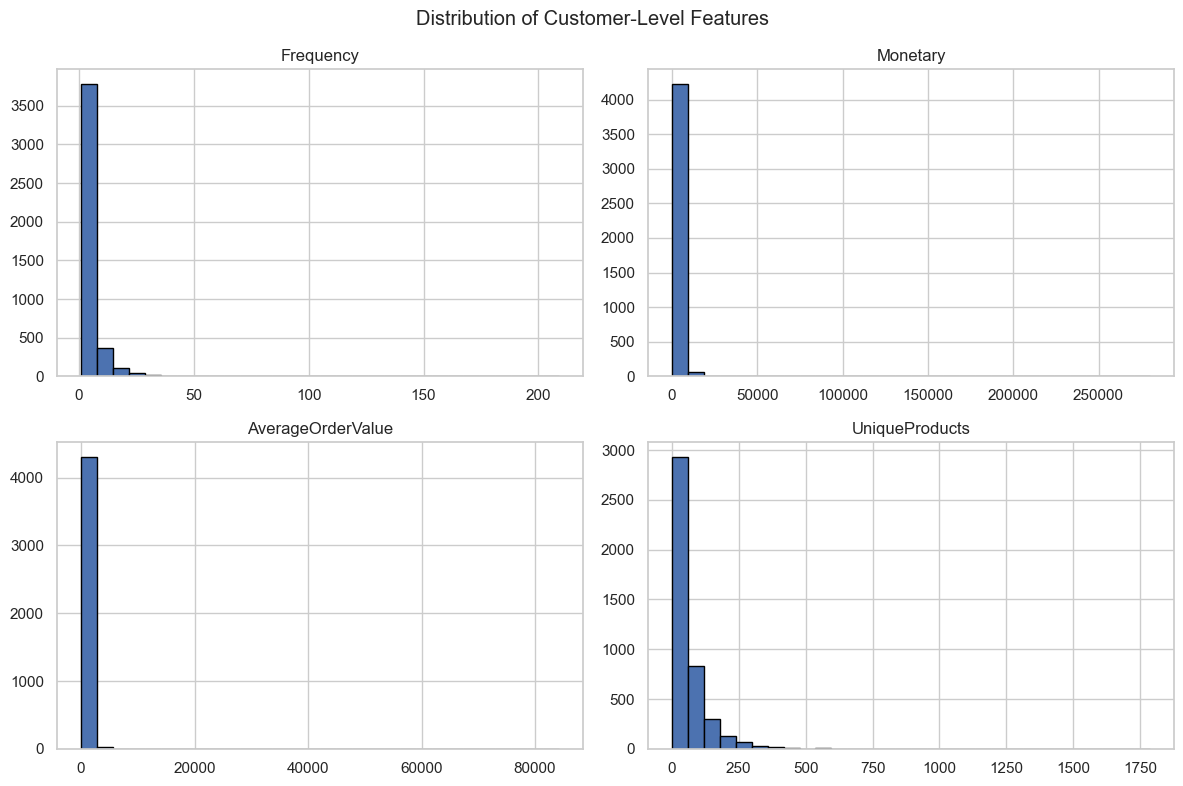

In [6]:
customer_features.hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Customer-Level Features")
plt.tight_layout()
plt.show()

## 5. Feature Transformation and Scaling

Customer purchasing features can have highly skewed distributions.

A log1p transformation is applied to reduce skewness. StandardScaler is
then used to standardize the transformed features so that they have
comparable scales.

The resulting scaled feature matrix will be used by both clustering
algorithms.

In [7]:
# Apply log1p transformation to reduce skewness
X_log = np.log1p(customer_features)

# Standardize the transformed features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

print("Original customer features:", customer_features.shape)
print("Scaled feature matrix:", X_scaled.shape)

print("\nMean of scaled features:")
print(np.round(X_scaled.mean(axis=0), 3))

print("\nStandard deviation of scaled features:")
print(np.round(X_scaled.std(axis=0), 3))

Original customer features: (4338, 4)
Scaled feature matrix: (4338, 4)

Mean of scaled features:
[-0. -0.  0.  0.]

Standard deviation of scaled features:
[1. 1. 1. 1.]


## 6. Model 1: K-Means Clustering

K-Means is an unsupervised clustering algorithm that partitions observations
into K clusters.

The algorithm assigns each observation to its nearest cluster centroid
and repeatedly updates the centroids until the assignments stabilize.

### Selecting the Number of Clusters

The Elbow method is used to help select an appropriate number of clusters.

For different values of K, the within-cluster sum of squared distances
(inertia) is calculated.

The resulting curve is examined for an elbow, where increasing K produces
diminishing improvements in inertia.

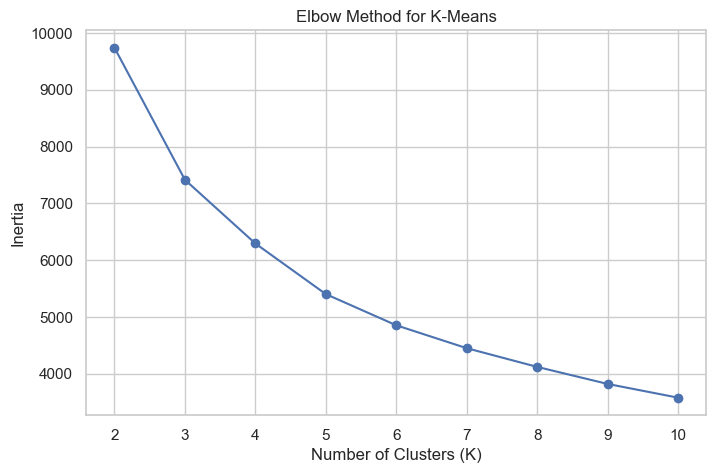

In [8]:
inertias = []

k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [9]:
KMEANS_K = 3

kmeans = KMeans(
    n_clusters=KMEANS_K,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

# Store cluster assignments
customer_features["KMeans_Cluster"] = kmeans_labels

print("K-Means fitted successfully.")
print("Number of clusters:", len(np.unique(kmeans_labels)))

print("\nCustomers in each cluster:")
print(
    customer_features["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

K-Means fitted successfully.
Number of clusters: 3

Customers in each cluster:
KMeans_Cluster
0    1162
1    1180
2    1996
Name: count, dtype: int64


### K-Means Evaluation

The K-Means model is evaluated using three internal clustering metrics.

1. Silhouette Score: Measures how well-separated the clusters are.
   Higher values generally indicate better-separated clusters.

2. Davies-Bouldin Index: Measures similarity between clusters.
   Lower values generally indicate better separation.

3. Calinski-Harabasz Index: Compares between-cluster dispersion
   with within-cluster dispersion. Higher values generally indicate
   better-defined clusters.

These metrics are calculated using the scaled customer features and
the cluster labels generated by K-Means.

In [10]:
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

kmeans_db = davies_bouldin_score(
    X_scaled,
    kmeans_labels
)

kmeans_ch = calinski_harabasz_score(
    X_scaled,
    kmeans_labels
)

kmeans_results = pd.DataFrame({
    "Algorithm": ["K-Means"],
    "Number of Clusters": [KMEANS_K],
    "Silhouette Score": [kmeans_silhouette],
    "Davies-Bouldin Index": [kmeans_db],
    "Calinski-Harabasz Index": [kmeans_ch]
})

display(kmeans_results.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,3,0.307,1.0623,2904.073


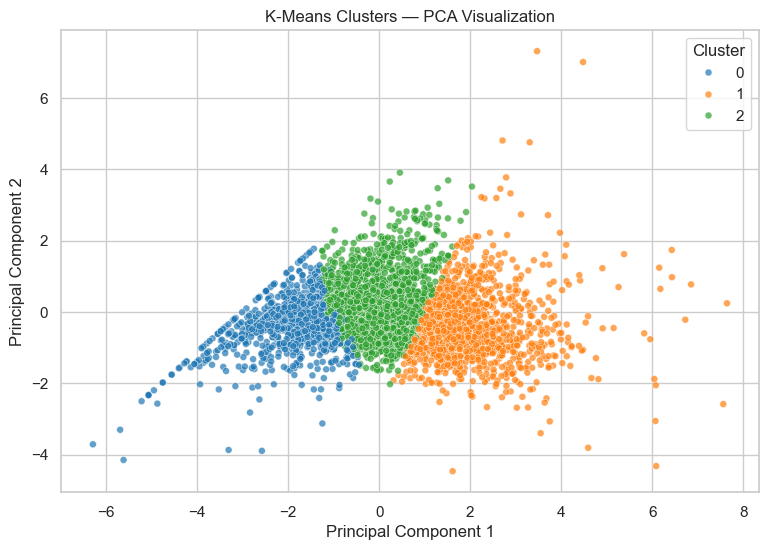

Explained variance by two principal components: 0.901


In [11]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

kmeans_pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": kmeans_labels
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=kmeans_pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=25,
    alpha=0.7
)

plt.title("K-Means Clusters — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

print(
    "Explained variance by two principal components:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

### K-Means Cluster Interpretation

The cluster summary describes the average purchasing behaviour of
customers assigned to each cluster.

The original customer-level features are used to interpret the clusters
in terms of purchasing frequency, total spending, average order value,
and product variety.

Cluster numbers are arbitrary identifiers. Their business meaning is
determined by examining the feature values rather than the numeric labels.

In [12]:
kmeans_summary = (
    customer_features
    .groupby("KMeans_Cluster")[feature_columns]
    .mean()
    .round(2)
)

print("Average customer features for each K-Means cluster:")
display(kmeans_summary)

print("\nNumber of customers in each cluster:")
display(
    customer_features["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .rename("Number of Customers")
    .to_frame()
)

Average customer features for each K-Means cluster:


,Frequency,Monetary,AverageOrderValue,UniqueProducts
KMeans_Cluster,,,,
0,1.49,211.53,153.83,13.00
1,10.36,5995.81,693.06,140.04
2,2.29,784.74,408.41,43.31



Number of customers in each cluster:


,Number of Customers
KMeans_Cluster,
0,1162
1,1180
2,1996


## 7. Model 2: Agglomerative Hierarchical Clustering

Agglomerative Hierarchical Clustering is an unsupervised algorithm that
initially treats each observation as an individual cluster.

At each step, it merges the closest clusters according to the selected
linkage strategy until the required number of clusters is obtained.

This project uses Ward linkage, which merges clusters to minimize the
increase in within-cluster variance.

A dendrogram is generated using a reproducible sample to visualize the
hierarchical relationships between customers.

In [13]:
# Use a reproducible sample to keep hierarchical clustering manageable
HIERARCHICAL_SAMPLE_SIZE = min(3000, len(X_scaled))

rng = np.random.default_rng(RANDOM_STATE)

sample_indices = rng.choice(
    len(X_scaled),
    size=HIERARCHICAL_SAMPLE_SIZE,
    replace=False
)

X_hier = X_scaled[sample_indices]

print("Full customer dataset:", X_scaled.shape)
print("Hierarchical clustering sample:", X_hier.shape)

Full customer dataset: (4338, 4)
Hierarchical clustering sample: (3000, 4)


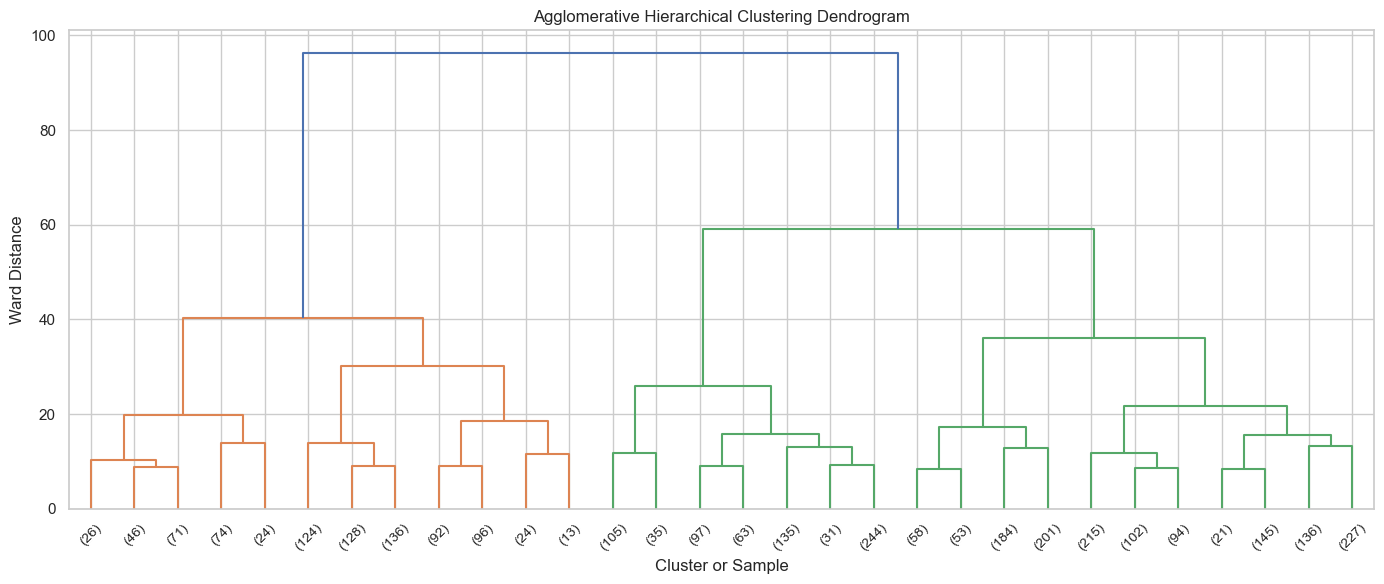

In [14]:
# Ward linkage is suitable for standardized numerical features
Z = linkage(X_hier, method="ward")

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Agglomerative Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster or Sample")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

In [15]:
HIERARCHICAL_K = 3

hierarchical = AgglomerativeClustering(
    n_clusters=HIERARCHICAL_K,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_hier)

print("Agglomerative clustering fitted successfully.")
print("Number of clusters:", len(np.unique(hierarchical_labels)))

print("\nCustomers in each cluster:")
print(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)

Agglomerative clustering fitted successfully.
Number of clusters: 3

Customers in each cluster:
0     854
1    1436
2     710
Name: count, dtype: int64


### Agglomerative Clustering Evaluation

The hierarchical clustering model is evaluated using the Silhouette
Score, Davies-Bouldin Index, and Calinski-Harabasz Index.

These metrics are calculated using the sampled standardized customer
features and their corresponding cluster labels.

PCA is also used to visualize the resulting clusters in two dimensions.

In [16]:
hier_silhouette = silhouette_score(
    X_hier,
    hierarchical_labels
)

hier_db = davies_bouldin_score(
    X_hier,
    hierarchical_labels
)

hier_ch = calinski_harabasz_score(
    X_hier,
    hierarchical_labels
)

hierarchical_results = pd.DataFrame({
    "Algorithm": ["Agglomerative Hierarchical"],
    "Number of Clusters": [HIERARCHICAL_K],
    "Silhouette Score": [hier_silhouette],
    "Davies-Bouldin Index": [hier_db],
    "Calinski-Harabasz Index": [hier_ch]
})

display(hierarchical_results.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Agglomerative Hierarchical,3,0.2695,1.1538,1711.4206


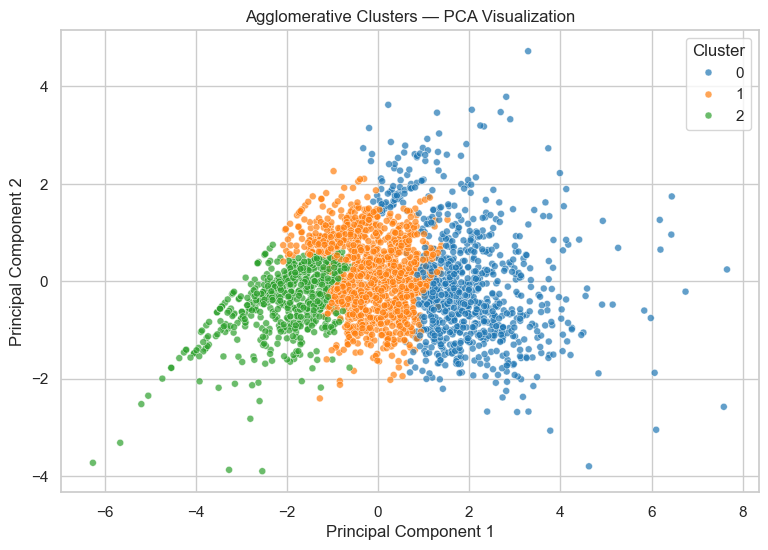

Explained variance by two principal components: 0.9013


In [17]:
hier_pca = PCA(n_components=2)

X_hier_pca = hier_pca.fit_transform(X_hier)

hier_pca_df = pd.DataFrame({
    "PC1": X_hier_pca[:, 0],
    "PC2": X_hier_pca[:, 1],
    "Cluster": hierarchical_labels
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=hier_pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=25,
    alpha=0.7
)

plt.title("Agglomerative Clusters — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

print(
    "Explained variance by two principal components:",
    round(hier_pca.explained_variance_ratio_.sum(), 4)
)

### t-SNE Visualization

t-SNE is a dimensionality-reduction technique that represents high-dimensional
data in a lower-dimensional space.

It is used here to visualize the K-Means cluster assignments in two dimensions.

The visualization is generated from a sample of customers because t-SNE
can be computationally expensive on large datasets.

The t-SNE plot is used for exploratory visualization and is not itself
a clustering algorithm.

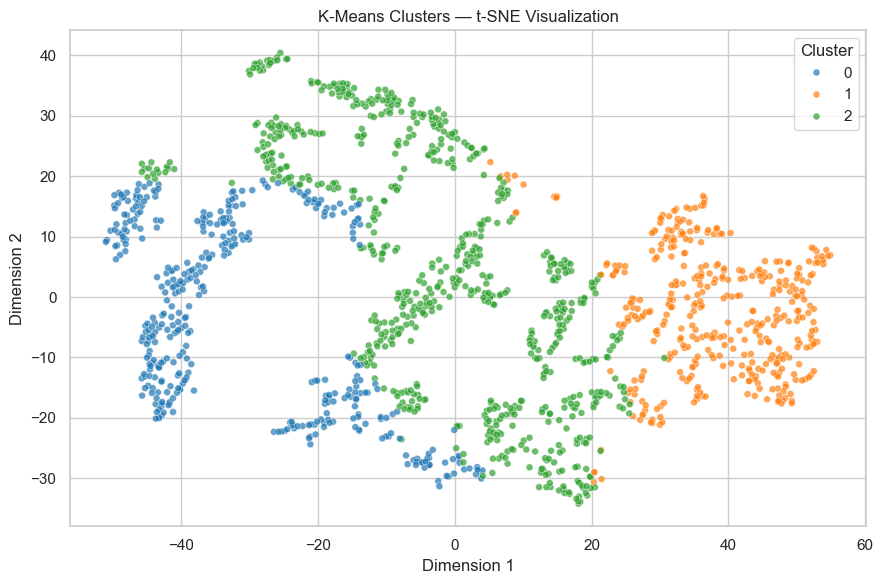

In [18]:
TSNE_SAMPLE_SIZE = min(1500, len(X_scaled))

tsne_indices = rng.choice(
    len(X_scaled),
    size=TSNE_SAMPLE_SIZE,
    replace=False
)

X_tsne_input = X_scaled[tsne_indices]
tsne_labels = kmeans_labels[tsne_indices]

tsne = TSNE(
    n_components=2,
    random_state=RANDOM_STATE,
    init="pca",
    learning_rate="auto",
    perplexity=min(30, (TSNE_SAMPLE_SIZE - 1) // 3),
    max_iter=1000
)

X_tsne = tsne.fit_transform(X_tsne_input)

tsne_df = pd.DataFrame({
    "Dimension 1": X_tsne[:, 0],
    "Dimension 2": X_tsne[:, 1],
    "Cluster": tsne_labels
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=tsne_df,
    x="Dimension 1",
    y="Dimension 2",
    hue="Cluster",
    palette="tab10",
    s=25,
    alpha=0.7
)

plt.title("K-Means Clusters — t-SNE Visualization")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 8. Comparative Evaluation

The final comparison presents the internal evaluation metrics for both
clustering algorithms.

The Silhouette Score is generally better when higher. The Davies-Bouldin
Index is generally better when lower, while the Calinski-Harabasz Index
is generally better when higher.

The results should be interpreted alongside the visualizations and the
feature profiles of the resulting clusters.

The two models use different amounts of data in this implementation:
K-Means is fitted on all eligible customers, while Agglomerative
Hierarchical Clustering is fitted on a reproducible sample. Their scores
should therefore be interpreted with this difference in mind.

In [19]:
comparison_results = pd.concat(
    [kmeans_results, hierarchical_results],
    ignore_index=True
)

display(comparison_results.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,3,0.3070,1.0623,2904.0730
1,Agglomerative Hierarchical,3,0.2695,1.1538,1711.4206


In [20]:
print("CLUSTERING PROJECT SUMMARY")
print("=" * 40)

print("\nCustomer feature dataset:")
print(customer_features[feature_columns].shape)

print("\nK-Means cluster sizes:")
print(
    pd.Series(kmeans_labels)
    .value_counts()
    .sort_index()
)

print("\nAgglomerative cluster sizes:")
print(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)

print("\nFinal evaluation comparison:")
display(comparison_results.round(4))

print("\nClustering analysis completed.")

CLUSTERING PROJECT SUMMARY

Customer feature dataset:
(4338, 4)

K-Means cluster sizes:
0    1162
1    1180
2    1996
Name: count, dtype: int64

Agglomerative cluster sizes:
0     854
1    1436
2     710
Name: count, dtype: int64

Final evaluation comparison:


,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,3,0.3070,1.0623,2904.0730
1,Agglomerative Hierarchical,3,0.2695,1.1538,1711.4206



Clustering analysis completed.
